In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from sklearn.model_selection import train_test_split

#### Part 1: Target Variable Selection

In [12]:
# load data

file_path = '../Data/CBP_TWQM_MAIN_WQ_2021_2026_surface.csv'
df = pd.read_csv(file_path)

df_pivot = df.pivot_table(
    index=['SampleDate','SampleTime'],
    columns = 'Parameter',
    values = 'MeasureValue'
).reset_index()

df_pivot.head()

Parameter,SampleDate,SampleTime,CHLA,DIN,DO,DON,DOP,KD,NH4F,NO23F,...,SECCHI,SIGMA_T,SPCOND,TDN,TDP,TN,TON,TP,TSS,WTEMP
0,2021-10-05,12:47:00,7.595,0.270,7.3,0.260,0.00940,0.9170,0.016,0.254,...,1.4,3.82561,14700.0,0.53,0.0131,0.747,0.477,0.0346,3.8,23.3
1,2021-11-17,11:57:00,17.444,0.444,10.4,0.286,0.02370,1.0270,0.009,0.435,...,1.6,6.71673,16300.0,0.73,0.0271,0.922,0.478,0.0486,6.8,12.8
2,2021-12-08,12:05:00,12.935,0.332,10.2,0.228,0.00705,0.7500,0.032,0.300,...,1.6,9.15105,20200.0,0.56,0.0096,0.736,0.404,0.0282,7.2,9.2
3,2022-03-15,13:29:00,20.292,0.482,11.9,0.278,0.00355,0.0000,0.010,0.472,...,1.2,7.38314,16300.0,0.76,0.0061,1.072,0.590,0.0243,4.8,6.6
4,2022-04-12,12:42:00,29.904,0.422,11.4,0.328,0.00460,1.0714,0.021,0.401,...,1.0,6.39514,15000.0,0.75,0.0088,1.104,0.682,0.0357,10.0,10.3


My target variable is going to be Dissolved Oxygen, because I find it to be among the more interesting features, and I think there are some interesting potential predictor variables that I would like to test out. For predictor variables, I am going to look into secchi depth to examine the light penetration that could be impacting photosynthesis, as well as chl-a to look at the biological productivity in the water. 

In [13]:
feature_col = ['SECCHI', 'CHLA']
target_col = 'DO'

In [14]:
df_clean = df_pivot[feature_col + [target_col]].dropna()

x = df_clean[feature_col]
y = df_clean[target_col]

#### Part 2: Model Implementation

In [15]:
# split into training and testing

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [16]:
# I am going to use linear regression, KNN, and MLP

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

In [17]:
# linear regression first 

model_lr = LinearRegression()
model_lr.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


I think this means the model is trained, now I'll do the other two.

In [59]:
# KNN

model_knn = KNeighborsRegressor(n_neighbors=2)
model_knn.fit(x_train,y_train)

,n_neighbors,12
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [30]:
# MLP
model_mlp = MLPRegressor(hidden_layer_sizes=(10,), max_iter=2000, random_state=42)
model_mlp.fit(x_train,y_train)

,loss,'squared_error'
,hidden_layer_sizes,"(10,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,2000
,shuffle,True


#### Part 3: Model Evaluation and Visualization

In [31]:
from sklearn.metrics import mean_squared_error, r2_score

In [32]:
# MLR
y_pred_lr = model_lr.predict(x_test)
print(f"Linear Regression -> R^2: {r2_score(y_test, y_pred_lr):.3f} | MSE: {mean_squared_error(y_test, y_pred_lr):.3f}")

Linear Regression -> R^2: -0.411 | MSE: 4.579


In [68]:
# KNN
y_pred_knn = model_knn.predict(x_test)
print(f"K Nearest Neighbors -> R^2: {r2_score(y_test, y_pred_knn):.3f} | MSE: {mean_squared_error(y_test, y_pred_knn):.3f}")

K Nearest Neighbors -> R^2: 0.368 | MSE: 2.050


In [88]:
# MLP
y_pred_mlp = model_mlp.predict(x_test)
print(f"Multi-Layer Perceptron -> R^2: {r2_score(y_test, y_pred_mlp):.3f} | MSE: {mean_squared_error(y_test, y_pred_mlp):.3f}")

Multi-Layer Perceptron -> R^2: -0.411 | MSE: 4.577


Now that I've run them all I want to make a plot.

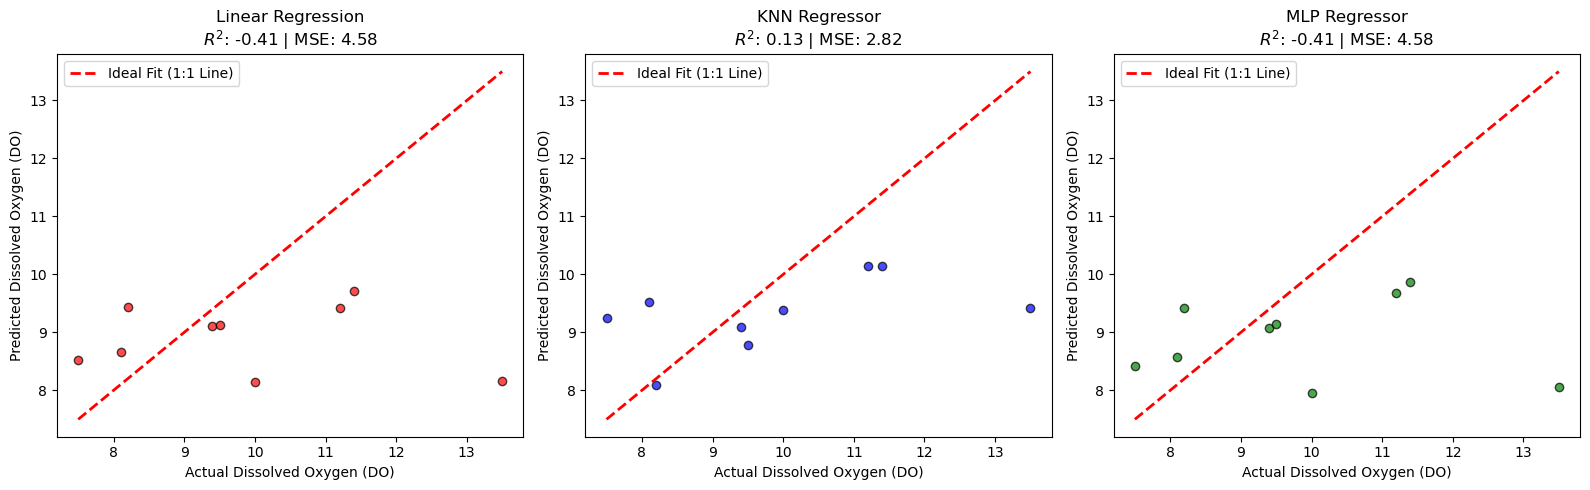

In [36]:
fig, axes = plt.subplots(1,3,figsize=(16,5))
models_data = [
    ("Linear Regression", y_pred_lr, "red"),
    ("KNN Regressor", y_pred_knn, "blue"),
    ("MLP Regressor", y_pred_mlp, "green")
]

for ax, (title, y_pred, color) in zip(axes, models_data):
    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    ax.scatter(y_test, y_pred, color=color, alpha=0.7, edgecolors='k')
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit (1:1 Line)')
    ax.set_title(f"{title}\n$R^2$: {r2:.2f} | MSE: {mse:.2f}")
    ax.set_xlabel("Actual Dissolved Oxygen (DO)")
    ax.set_ylabel("Predicted Dissolved Oxygen (DO)")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

#### Part 4: Hyperparameter Explanation

The KNN model ended up being the best, with the highest R^2 of 0.368 and a MSE of 2.050. It seems that it performed the best at handling the variations because it relied on pulling in local clusters of nearby water conditions. I chose to do only 2 neighbors after testing parameters from 1-20 and seeing that 2 yielded the highest R^2 value. The other two tests had much lower R^2, both in the negatives, and higher MSE, meaning that those models did not perform as well as the KNN value. I chose 10 as a starting value for the hidden layers in the MLP test, but even with testing many other parameters, I was not able to get to a positive R^2 value. The MLP model was not a good predictor of DO content. 